# 01 · The data problem: joining plant photos to a toxicity list

The hardest part of this project is not the neural network. It is
deciding when a photograph of a plant and a row in a toxicity table
refer to the same organism.

Neither dataset was built for this. Pl@ntNet-300K is a
species-identification benchmark: photographs labelled with scientific
names, assembled to study classification under ambiguity. The ASPCA list
is a veterinary reference, written for people to read. Nothing about
either was designed to line up with the other.

Getting the join wrong is not a data-cleaning annoyance here. It is how
a toxic plant ends up labelled safe. This notebook is about doing it
carefully, and about how much stays uncovered afterwards.

## 1. The two sources

**Pl@ntNet-300K v2** supplies the photographs: 306,087 images across
1,000 species, split 243,866 train / 31,115 validation / 31,106 test.
They come from the Pl@ntNet citizen-science platform, so they are field
photographs of plants outdoors, usually shot deliberately by someone
trying to identify them.

How those 1,000 species were chosen matters later, so it is worth
quoting. The authors did not sample species; they sampled **genera**:

> we choose to retain randomly selected genera and keep all species
> belonging to these genera. This choice aims to preserve the large
> amount of ambiguity present in the original database, as species
> belonging to the same genus tend to share visual features. The dataset
> presented in this paper is constructed by sampling uniformly at random
> only 10% of the genera of the whole Pl@ntNet database. We then retain
> only species with more than 4 images.
>
> Garcin et al., *Pl@ntNet-300K: a plant image dataset with high label
> ambiguity and a long-tailed distribution*, NeurIPS Datasets and
> Benchmarks 2021.

The ambiguity is deliberate. Keeping whole genera means the label space
is full of close relatives that look alike: v2's 1,000 species sit in
just 325 genera, and *Sedum* alone contributes 49 of them, *Hypericum*
37. That design decision is the reason genus-level toxicity matching is
both tempting and dangerous here, which sections 5 and 6 are about.

A version note that matters for every number in these notebooks: the
paper reports on **v1** (303 genera, 1,081 species) and this project
uses **v2** (325 genera, 1,000 species). Published baselines are not
directly comparable, which is why
[`02_training`](02_training.ipynb) retrains a benchmark rather than
quoting one.

**The ASPCA list** supplies the toxicity. Its cat-plant index was
scraped page by page, 983 plant pages, 982 of which parsed. The scraper
reads `robots.txt` once per run and honours the `Crawl-delay` it finds
there, which was 10 seconds at the time of writing.

One subtlety carries through the whole project: ASPCA's **"non-toxic"
means "will not poison your cat"**, not "safe" and not "edible". A
non-toxic plant can still cause mechanical injury or an upset stomach.
Every verdict this project emits says *likely safe*, never *safe*, for
that reason.

The hand-curated table that comes out of this is
[`data/toxicity.json`](../data/toxicity.json): 571 entries. The raw
scrape is kept separately as a first draft and never feeds the safety
path directly.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from plant_toxicity_checker import plantnet_labels, species_match
from plant_toxicity_checker.config import DEFAULT_RUN, TOXICITY_TABLE_PATH
from plant_toxicity_checker.toxicity import load_table

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 92}}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

OUTPUTS_DIR = Path("../outputs")
TABLE = load_table(TOXICITY_TABLE_PATH)
TOXICITY_INDEX = species_match.build_toxicity_index(TABLE)
SPECIES_ROWS = plantnet_labels.load_species_rows()

TOXIC_COLOR, SAFE_COLOR = "#b3202c", "#2e7d32"
GENUS_COLOR, NONE_COLOR = "#c77700", "#9e9e9e"

# Training-set size per species, read back from the per-species
# breakdown the shipped run already wrote, so this notebook never needs
# the image files themselves.
BREAKDOWN = json.loads(
    (OUTPUTS_DIR / DEFAULT_RUN /
     "species_breakdown_test_epoch30.json").read_text(encoding="utf-8")
)
TRAIN_COUNTS = sorted(s["train_count"] for s in BREAKDOWN["species"])
print(f"{len(SPECIES_ROWS)} PlantNet species, {len(TABLE)} toxicity-table "
      f"entries")

1000 PlantNet species, 571 toxicity-table entries


## 2. The long tail

Pl@ntNet-300K's photographs are not spread evenly across its species,
and the shape of that imbalance drives most of what happens in
[`02_training`](02_training.ipynb).

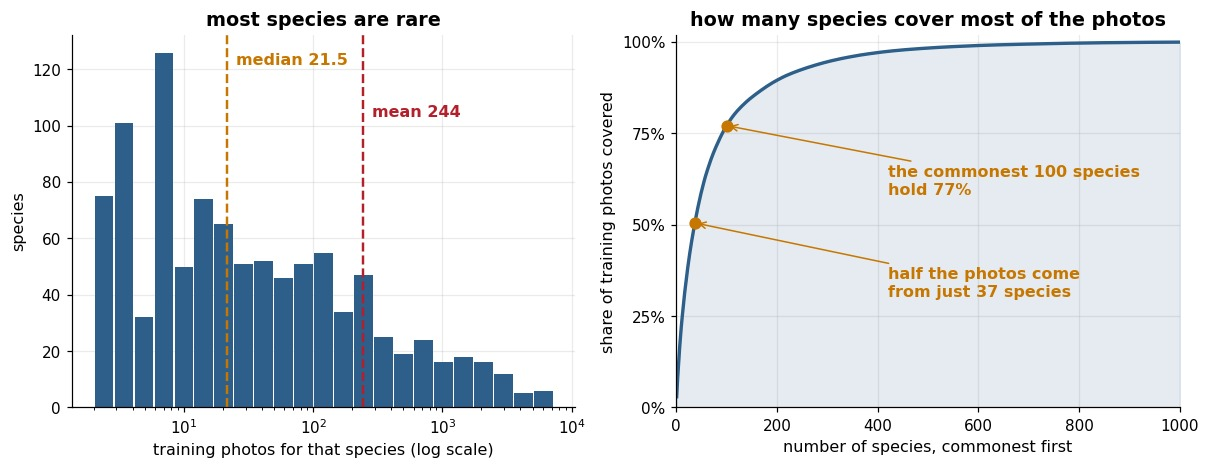

rarest 2   median 21.5   mean 243.9   commonest 7207   total 243,866
half the species have 21 training photos or fewer
75 species have 2 or fewer training photos


In [2]:
counts = np.array(TRAIN_COUNTS)
figure, axes = plt.subplots(1, 2, figsize=(13, 4.4))

axes[0].hist(counts, bins=np.logspace(np.log10(counts.min()),
                                      np.log10(counts.max()), 24),
             color="#2d5f8a", rwidth=0.92)
axes[0].set_xscale("log")
axes[0].set_xlabel("training photos for that species (log scale)",
                   fontsize=10.5)
axes[0].set_ylabel("species", fontsize=10.5)
axes[0].set_title("most species are rare", fontsize=12.5,
                  fontweight="bold")

# Mean and median are an order of magnitude apart, which is the whole
# shape of the problem in two numbers.
top = axes[0].get_ylim()[1]
for value, label, color, height, shown in (
        (np.median(counts), "median", "#c77700", 0.92,
         f"{np.median(counts):g}"),
        (counts.mean(), "mean", "#b3202c", 0.78,
         f"{counts.mean():.0f}")):
    axes[0].axvline(value, color=color, linestyle="--", linewidth=1.6)
    axes[0].text(value * 1.18, top * height, f"{label} {shown}",
                 color=color, fontsize=10.5, fontweight="bold")

# Species ordered COMMONEST first, against the cumulative share of
# photographs they account for. Read it as "how many species do I need
# before I have covered X% of the data".
ranked = np.sort(counts)[::-1]
cumulative = np.cumsum(ranked) / ranked.sum()
rank = np.arange(1, len(ranked) + 1)
axes[1].plot(rank, cumulative, color="#2d5f8a", linewidth=2.2)
axes[1].fill_between(rank, cumulative, color="#2d5f8a", alpha=0.12)

# Label positions are explicit: the curve leaves a wide empty region to
# the right, and both callouts live there rather than over the axes.
half_point = int(np.searchsorted(cumulative, 0.5)) + 1
MARKS = [
    (100, f"the commonest 100 species\nhold {cumulative[99]:.0%}",
     (420, 0.62)),
    (half_point, f"half the photos come\nfrom just {half_point} species",
     (420, 0.34)),
]
for position, label, textxy in MARKS:
    axes[1].plot([position], [cumulative[position - 1]], "o", color="#c77700",
                 markersize=7, zorder=3)
    axes[1].annotate(label, xy=(position, cumulative[position - 1]),
                     xytext=textxy, fontsize=10.5, color="#c77700",
                     fontweight="bold", va="center",
                     arrowprops={"arrowstyle": "->", "color": "#c77700"})
axes[1].set_xlim(0, len(ranked))
axes[1].set_ylim(0, 1.02)
axes[1].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axes[1].set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=10)
axes[1].set_xlabel("number of species, commonest first", fontsize=10.5)
axes[1].set_ylabel("share of training photos covered", fontsize=10.5)
axes[1].set_title("how many species cover most of the photos",
                  fontsize=12.5, fontweight="bold")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.set_axisbelow(True)
plt.show()

print(f"rarest {counts.min()}   median {np.median(counts):g}   "
      f"mean {counts.mean():.1f}   commonest {counts.max()}   "
      f"total {counts.sum():,}")
print(f"half the species have {np.sort(counts)[len(counts) // 2 - 1]} "
      f"training photos or fewer")
print(f"{(counts <= 2).sum()} species have 2 or fewer training photos")

The rarest species has **2** training photographs. The commonest,
*Daucus carota*, has **7,207**. Half the species have **21 or fewer**,
which is to say half the dataset's species would fit in a single batch.

Mean and median say it in two numbers: the mean is **244** photographs
per species, the median **21.5**. A mean an order of magnitude above the
median is the signature of a distribution where a few members carry
almost everything.

Counting from the other end makes it concrete: **half of all training
photographs come from just 37 species**, and the commonest 100 account
for 77% of them. The remaining 900 species share what is left.

These four buckets are used throughout the other notebooks, so they are
defined once here:

| Bucket | Species | Share of species |
|---|---|---|
| under 20 training photos | 477 | 48% |
| 20-49 | 149 | 15% |
| 50-199 | 183 | 18% |
| 200 or more | 191 | 19% |

Two consequences worth carrying forward. A model trained on this will be
good at the right-hand bucket and weak at the left, and plain accuracy
will report mostly on the right-hand one. And any *toxicity* coverage
measured per species will look much worse than coverage measured per
photograph, because the species the table covers tend to be common ones.

## 3. Why common names cannot be used

The obvious join is on common names: both sources have them, and they
are what people actually say. It does not work, and "lily" is the
clearest demonstration.

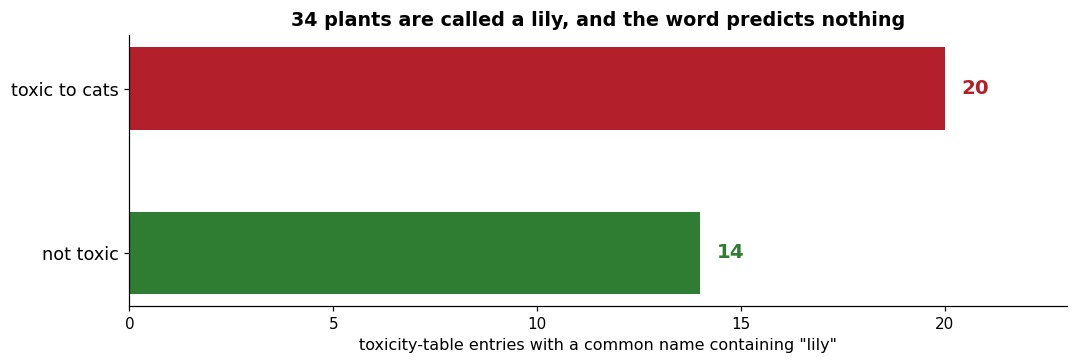

Same genus, near-identical common name, opposite answers:
   Cordyline australis    Palm Lily            toxic_to_cats=yes
   Cordyline rubra        Red Palm Lily        toxic_to_cats=no
   Lilium longiflorum     Easter Lily          toxic_to_cats=yes
   Echinopsis multiplex   Easter Lily Cactus   toxic_to_cats=no


In [3]:
def aspca_common_names(entry):
    """ASPCA's own common names, which the scrape keeps in the entry's
    notes. Nothing joins on these - they are here to show why."""
    match = re.search(r"ASPCA common name\(s\): (.+)", entry.notes or "")
    return [n.strip() for n in match.group(1).split(",")] if match else []


lilies = [
    (entry, [n for n in aspca_common_names(entry) if "lily" in n.lower()])
    for entry in TABLE
]
lilies = [(e, n) for e, n in lilies if n]
toxic = [(e, n) for e, n in lilies if e.toxic_to_cats == "yes"]
safe = [(e, n) for e, n in lilies if e.toxic_to_cats == "no"]

figure, axis = plt.subplots(figsize=(11, 3.2))
axis.barh([1], [len(toxic)], color=TOXIC_COLOR, height=0.5)
axis.barh([0], [len(safe)], color=SAFE_COLOR, height=0.5)
for y, group, color in ((1, toxic, TOXIC_COLOR), (0, safe, SAFE_COLOR)):
    axis.text(len(group) + 0.4, y, f"{len(group)}", va="center",
              fontsize=13, fontweight="bold", color=color)
axis.set_yticks([1, 0])
axis.set_yticklabels(["toxic to cats", "not toxic"], fontsize=11.5)
axis.set_xlim(0, max(len(toxic), len(safe)) + 3)
axis.set_xlabel("toxicity-table entries with a common name containing "
                "\"lily\"", fontsize=10.5)
axis.set_title(f"{len(lilies)} plants are called a lily, and the word "
               f"predicts nothing", fontsize=12.5, fontweight="bold")
plt.show()

print("Same genus, near-identical common name, opposite answers:")
for name in ("Cordyline australis", "Cordyline rubra",
             "Lilium longiflorum", "Echinopsis multiplex"):
    entry = TABLE.get(name)
    lily = next(n for n in aspca_common_names(entry) if "lily" in n.lower())
    print(f"   {name:22s} {lily:20s} toxic_to_cats={entry.toxic_to_cats}")

34 entries in the table carry a common name containing "lily". **20 are
toxic to cats and 14 are not.** The word carries no usable signal.

The pairs are worse than the aggregate. *Cordyline australis* is sold as
Palm Lily and is toxic; *Cordyline rubra* is Red Palm Lily and is not.
Easter Lily (*Lilium longiflorum*) causes fatal kidney failure in cats;
Easter Lily Cactus (*Echinopsis multiplex*) is harmless. A join on
either string gets one of each pair wrong, and the direction of the
error is not controllable.

So matching happens on **scientific name only**, everywhere in this
project, and common names are kept as human-readable notes that nothing
joins on.

Worth noting for section 7: *Lilium*, *Hemerocallis*, *Hippeastrum* and
*Spathiphyllum*, the genera that make lilies the canonical cat hazard,
have **no species at all** in Pl@ntNet-300K v2. The most famous poisoning
risk for cats is outside the label space entirely. The common-name
problem is real, but it is a problem inside the toxicity table rather
than at the join with the photographs.

## 4. Matching on scientific names

A scientific name as written carries more than the organism:
*Hypericum perforatum* **L.** names Linnaeus as the describing
authority, and that authority varies between sources for the same plant.
Matching therefore parses each name down to **(genus, epithet)** and
discards everything else.

In [4]:
AWKWARD = [
    ("Hypericum perforatum L.", "authority dropped"),
    ("Metasequoia glyptostroboides Hu & W.C.Cheng", "multi-word authority"),
    ("Neltuma glandulosa (Torr.) Britton & Rose", "parenthetical authority"),
    ("Hypericum \u00d7 inodorum Mill.", "hybrid marker skipped"),
    ("Hemerocallis spp.", "genus placeholder, no epithet"),
    ("Schefflera spp.", "genus placeholder, no epithet"),
    ("Sedum morganianum, burrito", "text after the comma ignored"),
]
width = max(len(name) for name, _ in AWKWARD)
for name, why in AWKWARD:
    genus, epithet = species_match.parse_scientific_name(name)
    parsed = f"({genus}, {epithet})"
    print(f"{name:<{width}}  ->  {parsed:<28}  {why}")

hybrids = [r for r in SPECIES_ROWS if "\u00d7" in r["full_species"]]
placeholders = [e for e in TABLE if species_match.is_genus_placeholder(e)]
print(f"\n{len(hybrids)} of {len(SPECIES_ROWS)} PlantNet names are hybrids")
print(f"{len(placeholders)} of {len(TABLE)} table entries are genus "
      f"placeholders")

Hypericum perforatum L.                      ->  (hypericum, perforatum)       authority dropped
Metasequoia glyptostroboides Hu & W.C.Cheng  ->  (metasequoia, glyptostroboides)  multi-word authority
Neltuma glandulosa (Torr.) Britton & Rose    ->  (neltuma, glandulosa)         parenthetical authority
Hypericum × inodorum Mill.                   ->  (hypericum, inodorum)         hybrid marker skipped
Hemerocallis spp.                            ->  (hemerocallis, None)          genus placeholder, no epithet
Schefflera spp.                              ->  (schefflera, None)            genus placeholder, no epithet
Sedum morganianum, burrito                   ->  (sedum, morganianum)          text after the comma ignored

16 of 1000 PlantNet names are hybrids
105 of 571 table entries are genus placeholders


Four behaviours are worth seeing explicitly.

**Authorities are dropped.** Only the first two word-like tokens matter,
so `Metasequoia glyptostroboides Hu & W.C.Cheng` and the same species
written by another source both reduce to the same key.

**Hybrid markers disappear.** The tokeniser matches ASCII letters and
hyphens only, so the `×` in `Hypericum × inodorum` is skipped
rather than mistaken for an epithet. 16 of PlantNet's 1,000 names are
hybrids written this way.

**Qualifiers are not epithets.** `spp`, `sp`, `cv`, `var`, `ssp` and `x`
are rejected, so `Hemerocallis spp.` parses to a genus with **no**
epithet. 105 of the table's 571 entries are genus placeholders like
this, and they are treated differently from a specific species: ASPCA is
making a genus-wide claim, which is stronger evidence than us noticing
that some other species in the genus happens to be toxic.

**Only text before the first comma is read**, because ASPCA entries
sometimes list alternate names after one.

That produces three outcomes per species: an **exact** match on genus
and epithet, a **genus-only** match, or nothing.

## 5. What the join yields

Running that match for all 1,000 PlantNet species against all 571 table
entries gives seven categories, which differ in how much they justify.

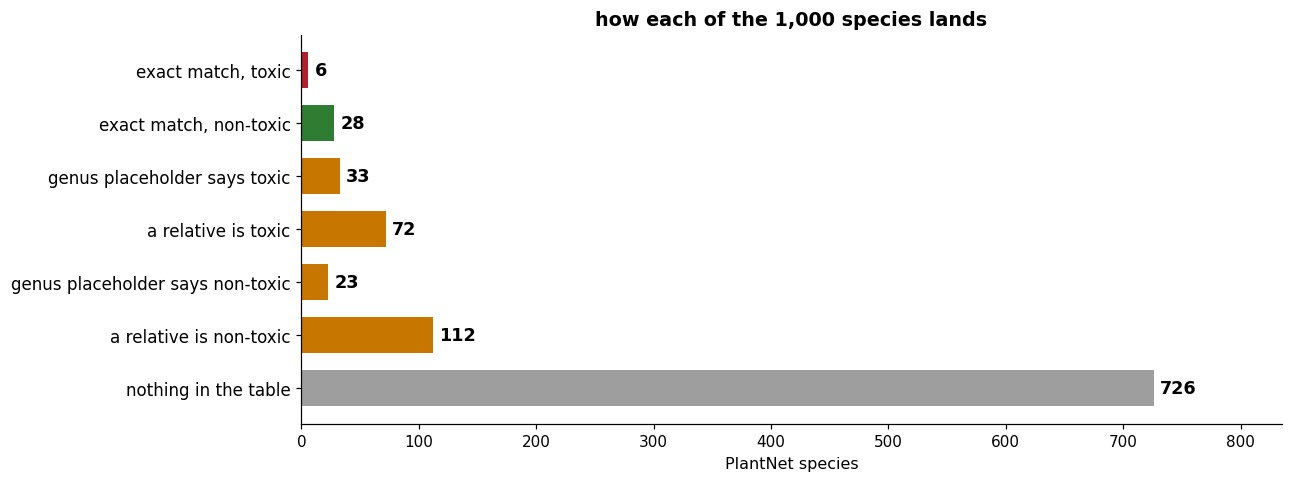

exact 34   genus-level only 240   no match 726


In [5]:
categories = Counter(
    species_match.toxicity_category(
        species_match.lookup_toxicity(row["species"], TOXICITY_INDEX))
    for row in SPECIES_ROWS
)

ORDER = [
    ("exact - toxic", "exact match, toxic", TOXIC_COLOR),
    ("exact - non-toxic", "exact match, non-toxic", SAFE_COLOR),
    ("genus - toxic (direct)", "genus placeholder says toxic", GENUS_COLOR),
    ("genus - toxic (inferred)", "a relative is toxic", GENUS_COLOR),
    ("genus - non-toxic (direct)", "genus placeholder says non-toxic",
     GENUS_COLOR),
    ("genus - non-toxic (inferred)", "a relative is non-toxic", GENUS_COLOR),
    ("no match", "nothing in the table", NONE_COLOR),
]

figure, axis = plt.subplots(figsize=(11.5, 4.6))
labels = [label for _, label, _ in ORDER]
values = [categories[key] for key, _, _ in ORDER]
colors = [color for _, _, color in ORDER]
positions = range(len(ORDER))[::-1]
bars = axis.barh(list(positions), values, color=colors, height=0.68)
axis.bar_label(bars, labels=[f"{v}" for v in values], padding=4,
               fontsize=11.5, fontweight="bold")
axis.set_yticks(list(positions))
axis.set_yticklabels(labels, fontsize=11)
axis.set_xlim(0, max(values) * 1.15)
axis.set_xlabel("PlantNet species", fontsize=10.5)
axis.set_title("how each of the 1,000 species lands", fontsize=12.5,
               fontweight="bold")
plt.show()

exact = sum(v for k, v in categories.items() if k.startswith("exact"))
genus = sum(v for k, v in categories.items() if k.startswith("genus"))
print(f"exact {exact}   genus-level only {genus}   "
      f"no match {categories['no match']}")

The headline split is **34 exact, 240 genus-level only, 726 nothing**.

Within the genus-level group the distinction that matters is *who* is
generalising. A **direct** match means the table's own entry is a genus
placeholder, so ASPCA is making the genus-wide claim. An **inferred**
match means only a different, specific species in that genus carries the
signal, and the generalisation is ours. A toxic signal always wins over
a non-toxic one within a genus, so a non-toxic relative can never cancel
out a toxic one.

None of this is the verdict path. The verdict path uses exact,
hand-verified entries and nothing else. These categories exist so the
*training* objective can use a weaker signal, and so this notebook can
be honest about the size of the gap.

## 6. Verified versus inferred, and where each is allowed

The rule that governs the whole project: **genus-inferred toxicity is
good enough to shape a training loss, never good enough to tell someone
their cat is safe.**

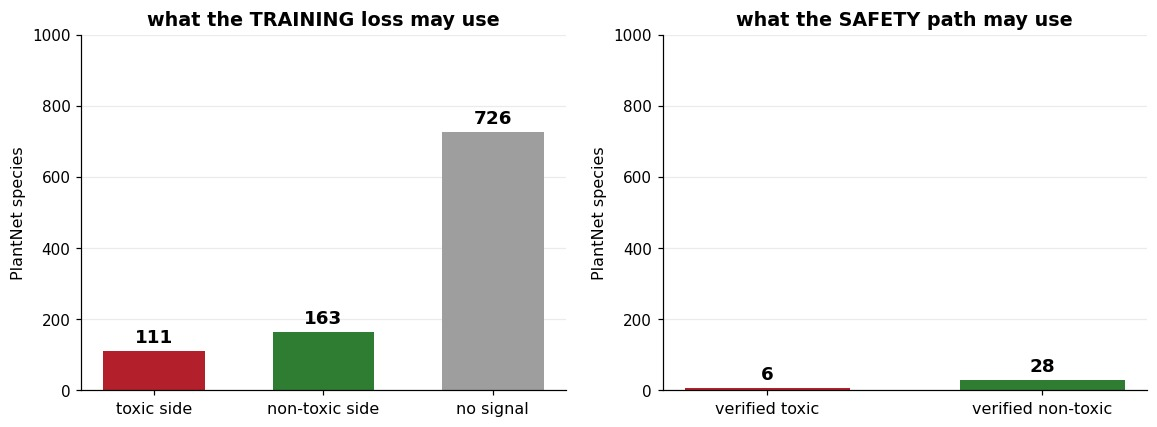

training signal covers 274 of 1,000 species; the safety path covers 34


In [6]:
SIDE_LABEL = {"toxic": "toxic side", "non_toxic": "non-toxic side",
              None: "no signal"}
sides = Counter()
for row in SPECIES_ROWS:
    match = species_match.lookup_toxicity(row["species"], TOXICITY_INDEX)
    sides[SIDE_LABEL[species_match.toxicity_side(match)]] += 1

verified = Counter()
for row in SPECIES_ROWS:
    match = species_match.lookup_toxicity(row["species"], TOXICITY_INDEX)
    if match.status == "exact" and match.exact_row.verified:
        verified["verified toxic" if match.exact_row.toxic_to_cats == "yes"
                 else "verified non-toxic"] += 1

figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

train_order = ["toxic side", "non-toxic side", "no signal"]
axes[0].bar(range(3), [sides[k] for k in train_order],
            color=[TOXIC_COLOR, SAFE_COLOR, NONE_COLOR], width=0.6)
axes[0].bar_label(axes[0].containers[0],
                  labels=[str(sides[k]) for k in train_order], padding=3,
                  fontsize=12, fontweight="bold")
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(train_order, fontsize=10.5)
axes[0].set_title("what the TRAINING loss may use", fontsize=12.5,
                  fontweight="bold")

safety_order = ["verified toxic", "verified non-toxic"]
axes[1].bar(range(2), [verified[k] for k in safety_order],
            color=[TOXIC_COLOR, SAFE_COLOR], width=0.6)
axes[1].bar_label(axes[1].containers[0],
                  labels=[str(verified[k]) for k in safety_order], padding=3,
                  fontsize=12, fontweight="bold")
axes[1].set_xticks(range(2))
axes[1].set_xticklabels(safety_order, fontsize=10.5)
axes[1].set_title("what the SAFETY path may use", fontsize=12.5,
                  fontweight="bold")

for axis in axes:
    axis.set_ylim(0, 1000)
    axis.set_ylabel("PlantNet species", fontsize=10.5)
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
plt.show()

print(f"training signal covers {sides['toxic side'] + sides['non-toxic side']}"
      f" of 1,000 species; the safety path covers {sum(verified.values())}")

Two populations, two permissions.

The **training signal** is allowed the whole inferred structure, because
a wrong weight on a loss term costs accuracy, not safety. 111 species
land on the toxic side, 163 on the non-toxic side, and the 726 with no
signal are excluded from the cost term rather than guessed at. That is
what [`02_training`](02_training.ipynb)'s toxicity-aware term consumes.

The **safety path** is allowed only exact, hand-verified entries: 34
species, 28 non-toxic and 6 toxic. LIKELY SAFE additionally requires
that every plausible alternative clears the same bar, so the effective
set is smaller still.

The asymmetry is deliberate. Shrinking the verified set makes the system
more cautious and less useful; it cannot make it unsafe. Letting
inferred signal into the verdict path would do the reverse.

## 7. Coverage is the bottleneck

"Verify more rows" is the obvious thing to ask for, so it is worth
measuring rather than assuming. Every validation photograph was run
twice: once against the real table, and once against a table where
every non-toxic row that **already exists** counts as verified. Toxic
rows were left alone, since verifying those cannot unlock LIKELY SAFE.

**The result is zero.** Not a small gain: no photograph changed tier.

In [7]:
ceiling = json.loads(
    (OUTPUTS_DIR / DEFAULT_RUN / "verification_ceiling_val.json")
    .read_text(encoding="utf-8")
)
assert ceiling["real"] == ceiling["all_non_toxic_rows_verified"]
print(f"photos that changed tier when every existing non-toxic row was "
      f"treated as verified: {sum(ceiling['flipped'].values())}")

unverified = [
    row["species"] for row in SPECIES_ROWS
    if (match := species_match.lookup_toxicity(row["species"],
                                               TOXICITY_INDEX)).status
    == "exact" and match.exact_row.toxic_to_cats == "no"
    and not match.exact_row.verified
]
print(f"PlantNet species with an exact non-toxic row still unverified: "
      f"{len(unverified)}")

photos that changed tier when every existing non-toxic row was treated as verified: 0
PlantNet species with an exact non-toxic row still unverified: 0


The reason is simple once checked. Of the 28 PlantNet species with an
exact non-toxic row, **28 are already hand-verified**. There is no
backlog. Verification is not the bottleneck, and any plan built around
clearing one is aimed at nothing.

The actual bottleneck is **absence**. Grouping validation photographs by
what the table knows about their true species: roughly a sixth have an
exact row, a fifth have only genus-level signal, and **two thirds have
nothing at all**. By species the picture is worse still, because the
covered species are disproportionately common ones, exactly as section 2
predicted.

Set against the modelling effort, the comparison is blunt. Going from
the ResNet-18 benchmark to the shipped ConvNeXt V2-Tiny cost roughly 35
hours of training and bought 7 points of macro-average top-1. It moved
the share of photographs that can reach LIKELY SAFE by nothing, because
that ceiling is set by the table and not by the model. The cheapest
real improvement available to this project is someone sitting down with
the ASPCA list and writing rows for species that have none.

[`03_safety_logic`](03_safety_logic.ipynb) picks up from here and shows
how each of these categories is allowed to affect a verdict.

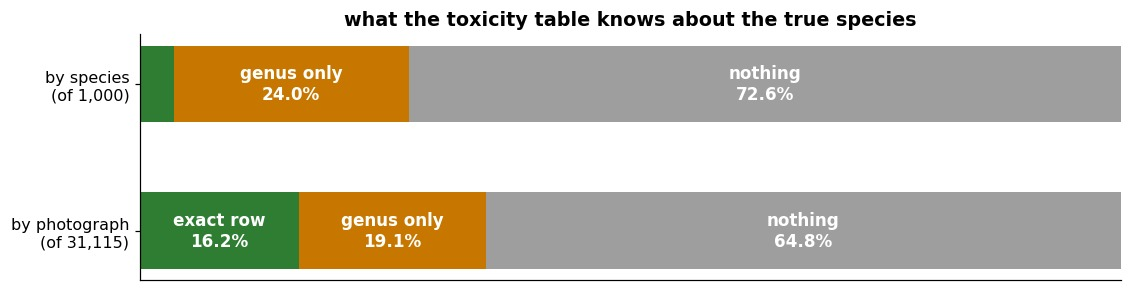

exact row     34 species ( 3.4%)    5,027 photos (16.2%)
genus only   240 species (24.0%)    5,938 photos (19.1%)
nothing      726 species (72.6%)   20,150 photos (64.8%)


In [8]:
# Coverage counted two ways. By species treats a rare orchid and
# Daucus carota alike; by photograph weights them as a user would meet
# them. Neither alone is honest, so both are shown.
val = json.loads(
    (OUTPUTS_DIR / DEFAULT_RUN /
     "species_breakdown_val_epoch30.json").read_text(encoding="utf-8")
)
SHORT_NAME = {row["full_species"]: row["species"] for row in SPECIES_ROWS}


def coverage_of(name):
    category = species_match.toxicity_category(
        species_match.lookup_toxicity(name, TOXICITY_INDEX))
    if category.startswith("exact"):
        return "exact row"
    return "genus only" if category.startswith("genus") else "nothing"


by_species, by_photo = Counter(), Counter()
for entry in val["species"]:
    name = SHORT_NAME.get(entry["name"], entry["name"])
    group = coverage_of(name)
    by_species[group] += 1
    by_photo[group] += entry["n_eval"]

GROUPS = [("exact row", SAFE_COLOR), ("genus only", GENUS_COLOR),
          ("nothing", NONE_COLOR)]
figure, axis = plt.subplots(figsize=(11.5, 2.9))
for index, (counts, title) in enumerate(
        ((by_species, "by species (of 1,000)"),
         (by_photo, "by photograph (of 31,115)"))):
    total = sum(counts.values())
    left = 0.0
    for group, color in GROUPS:
        share = counts[group] / total
        axis.barh(index, share, left=left, color=color, height=0.52)
        if share >= 0.10:
            axis.text(left + share / 2, index,
                      f"{group}\n{share:.1%}", ha="center", va="center",
                      color="white", fontsize=11, fontweight="bold")
        left += share
axis.set_yticks([0, 1])
axis.set_yticklabels(["by species\n(of 1,000)",
                      "by photograph\n(of 31,115)"], fontsize=10.5)
axis.set_xlim(0, 1)
axis.set_xticks([])
axis.invert_yaxis()
axis.set_title("what the toxicity table knows about the true species",
               fontsize=12.5, fontweight="bold")
plt.show()

for group, _ in GROUPS:
    print(f"{group:11s} {by_species[group]:4d} species "
          f"({by_species[group] / 1000:5.1%})   "
          f"{by_photo[group]:6,} photos "
          f"({by_photo[group] / sum(by_photo.values()):5.1%})")